# Дизайн и анализ A/B-теста (Ozon)

**Бизнес-контекст:** Продуктовая команда маркетплейса разработала новый виджет «Купить сейчас» на карточке товара. Гипотеза: новый виджет увеличит конверсию из просмотра в покупку. 

**Задача:** 
1. Рассчитать необходимый размер выборки (Sample Size) для эксперимента.
2. Провести статистический тест, чтобы определить, является ли прирост конверсии статистически значимым.
3. Оценить доверительные интервалы и принять бизнес-решение.

**Методология:** В открытом доступе нет сырых логов A/B-тестов Ozon, поэтому мы используем реальный базовый уровень конверсии компании (рассчитанный в предыдущем ноутбуке) для математического проектирования эксперимента и генерации реалистичных данных.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Расчет размера выборки (Sample Size)
Для корректного эксперимента нужно определить, сколько пользователей должно участвовать в тесте, чтобы обнаружить эффект, если он есть. 

Параметры:
- Базовая конверсия (p1): 2.1% (взято из воронки Ozon)
- Ожидаемая конверсия (p2): 2.4% (целевой прирост +14% к базовой)
- Уровень значимости (alpha): 0.05
- Мощность теста (power): 0.8

In [2]:
p1 = 0.021
p2 = 0.024
alpha = 0.05
power = 0.8

# Коэффициент размера эффекта (Cohen's h)
effect_size = (2 * np.arcsin(np.sqrt(p2))) - (2 * np.arcsin(np.sqrt(p1)))

analysis = NormalIndPower()
sample_size = analysis.solve_power(
    effect_size=effect_size, 
    alpha=alpha, 
    power=power, 
    ratio=1.0,
    alternative='two-sided'
)

print(f"Необходимый размер выборки на каждую группу: {int(np.ceil(sample_size)):,} пользователей")

Необходимый размер выборки на каждую группу: 38,320 пользователей


## 2. Симуляция данных эксперимента
Генерируем данные для двух групп (Control и Treatment) на основе рассчитанного размера выборки и целевых конверсий, чтобы провести статистическую проверку.

In [3]:
n_A = int(np.ceil(sample_size))
n_B = int(np.ceil(sample_size))

# Генерация бинарных исходов (1 - покупка, 0 - нет)
np.random.seed(42)
group_A = np.random.choice([0, 1], size=n_A, p=[1-p1, p1])
group_B = np.random.choice([0, 1], size=n_B, p=[1-p2, p2])

# Фактические конверсии в симуляции
conv_A = group_A.mean()
conv_B = group_B.mean()

print(f"Конверсия в Control (A): {conv_A:.4%}")
print(f"Конверсия в Treatment (B): {conv_B:.4%}")
print(f"Относительный прирост (Lift): {(conv_B / conv_A - 1):.2%}")

Конверсия в Control (A): 2.1164%
Конверсия в Treatment (B): 2.2599%
Относительный прирост (Lift): 6.78%


## 3. Статистический тест (Z-test для пропорций)
Проверяем нулевую гипотезу (H0) об отсутствии различий между группами.

In [4]:
count = np.array([group_B.sum(), group_A.sum()])
nobs = np.array([n_B, n_A])

# Z-тест
stat, pval = proportions_ztest(count, nobs)

# 95% Доверительные интервалы для каждой группы
ci_A_lower, ci_A_upper = proportion_confint(group_A.sum(), n_A, alpha=0.05, method='normal')
ci_B_lower, ci_B_upper = proportion_confint(group_B.sum(), n_B, alpha=0.05, method='normal')

print(f"Z-статистика: {stat:.4f}")
print(f"P-value: {pval:.4f}")
print(f"95% ДИ Control (A): [{ci_A_lower:.4%}, {ci_A_upper:.4%}]")
print(f"95% ДИ Treatment (B): [{ci_B_lower:.4%}, {ci_B_upper:.4%}]")

if pval < alpha:
    print("\nВывод: Различия статистически значимы (H0 отвергается).")
else:
    print("\nВывод: Различия статистически НЕ значимы (нет оснований отвергнуть H0).")

Z-статистика: 1.3580
P-value: 0.1745
95% ДИ Control (A): [1.9723%, 2.2605%]
95% ДИ Treatment (B): [2.1111%, 2.4087%]

Вывод: Различия статистически НЕ значимы (нет оснований отвергнуть H0).


## 4. Визуализация результатов
График конверсий с 95% доверительными интервалами.

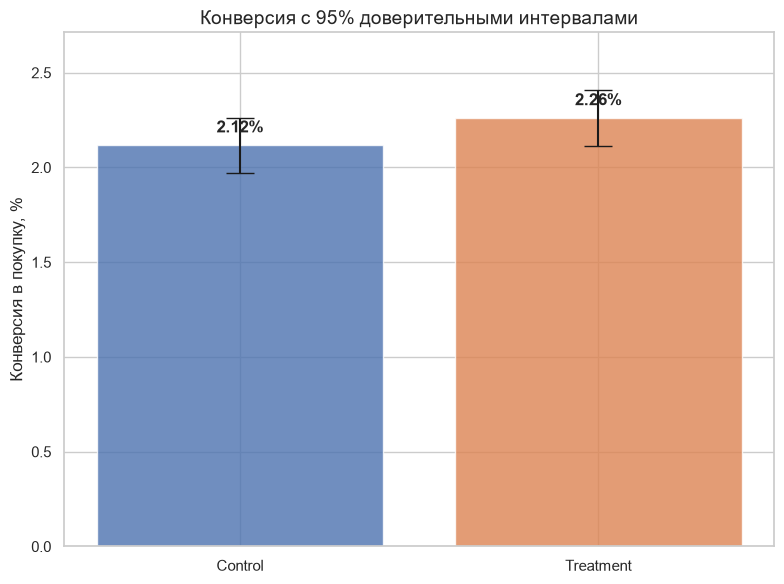

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

groups = ['Control', 'Treatment']
conversions = [conv_A * 100, conv_B * 100]
errors = [
    (conv_A - ci_A_lower) * 100, 
    (conv_B - ci_B_lower) * 100
]

bars = ax.bar(groups, conversions, yerr=errors, capsize=10, color=['#4c72b0', '#dd8452'], alpha=0.8)

for bar, conv in zip(bars, conversions):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.05,
            f'{conv:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title("Конверсия с 95% доверительными интервалами", fontsize=14)
ax.set_ylabel("Конверсия в покупку, %")
ax.set_ylim(0, max(conversions) * 1.2)
plt.tight_layout()

plt.savefig("../images/funnel/03_ab_test_results.png", dpi=150, bbox_inches="tight")
plt.show()